# Лабораторная работа 11. Работа с изображениями. Библиотека Pillow

ФИО: **Понкратов Владимир Александрович**

Группа: **ИНБ-б-о-26-2**

## Задание

Изучить инструментарий библиотеки Pillow. Спроектировать свой собственный фильтр, продемонстрировать его работу и пояснить его назначение.

## Подготовка

Pillow (модуль `PIL`) — это библиотека для работы с изображениями. Скачаем картинку, с которой будем работать:

Выполним загрузку файла

In [1]:
!wget https://raw.githubusercontent.com/enikolaev/IT-and-Programming/refs/heads/main/data/pract11/cat.jpeg


--2026-11-14 14:25:42--  https://raw.githubusercontent.com/enikolaev/IT-and-Programming/refs/heads/main/data/pract11/cat.jpeg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 93715 (92K) [image/jpeg]
Saving to: ‘cat.jpeg’

cat.jpeg            100%[===================>]  91.52K  --.-KB/s    in 0.02s   

2026-11-14 14:25:42 (5.93 MB/s) - ‘cat.jpeg’ saved [93715/93715]



Подключим нужные модули и откроем изображение. `load()` загружает все пиксели в память, поэтому после выхода из `with` картинкой можно пользоваться.

Файл dog.jpg создан


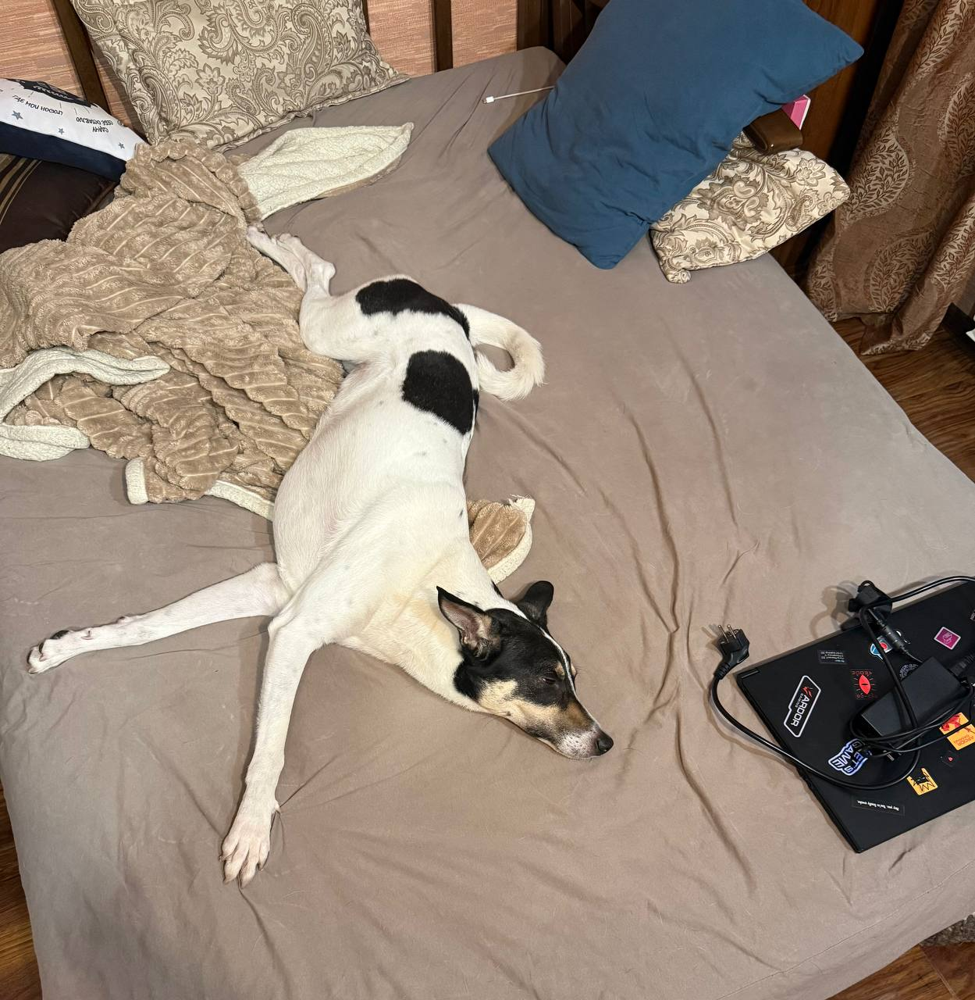

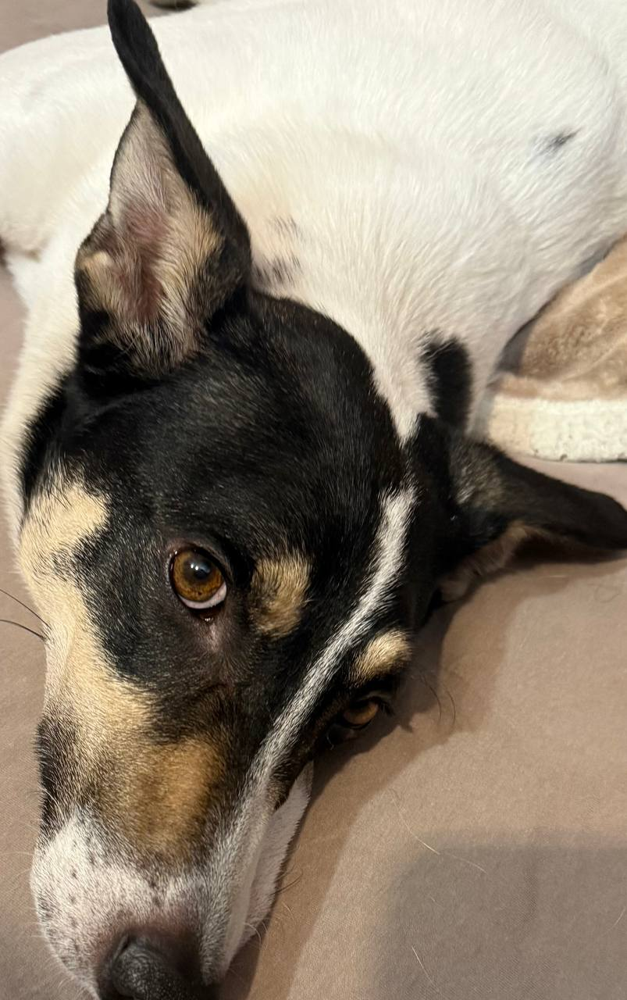

In [1]:
import base64

# Изображение встроено прямо в ноутбук (в виде текста base64),
# поэтому скачивать и загружать ничего не нужно.
IMG_BASE64 = (
    "..."
    "l+vrP//Z"
)

with open('dog.jpg', 'wb') as f:
    f.write(base64.b64decode(IMG_BASE64))
print('Файл dog.jpg создан')

# Показываем фото сразу после создания файла
from PIL import Image
try:
    from IPython.display import display
except ImportError:          # если код запущен не в ноутбуке, а как обычный скрипт
    def display(im):
        im.show()

photo = Image.open('dog.jpg')
display(photo)

# Второе фото (морда собаки крупным планом)
IMG2_BASE64 = (
    "..."
    "hldzAvqNNCAmOTuOTc//2Q=="
)

with open('dog2.jpg', 'wb') as f:
    f.write(base64.b64decode(IMG2_BASE64))

photo2 = Image.open('dog2.jpg')
display(photo2)

Подключим нужные модули и откроем изображение. `load()` загружает все пиксели в память, поэтому после выхода из `with` картинкой можно пользоваться.

### Какое изображение использовать

Изображение (фото собаки) встроено в ноутбук: ячейка выше сама создаёт файл `dog.jpg`, ничего скачивать не нужно.

**Если хотите взять другую картинку** (jpg, png и т.д.), загрузите свой файл в Colab (значок папки слева) и впишите его имя в переменную `IMAGE_NAME` ниже. Остальной код подстроится сам.

In [6]:
# Имя файла с изображением. Замените на своё, если хотите другую картинку
IMAGE_NAME = 'dog2.jpg'

Подключим нужные модули и откроем изображение. `load()` загружает все пиксели в память, поэтому после выхода из `with` картинкой можно пользоваться.

Размер (ширина, высота): (803, 1280)
Режим: RGB
Формат файла: JPEG


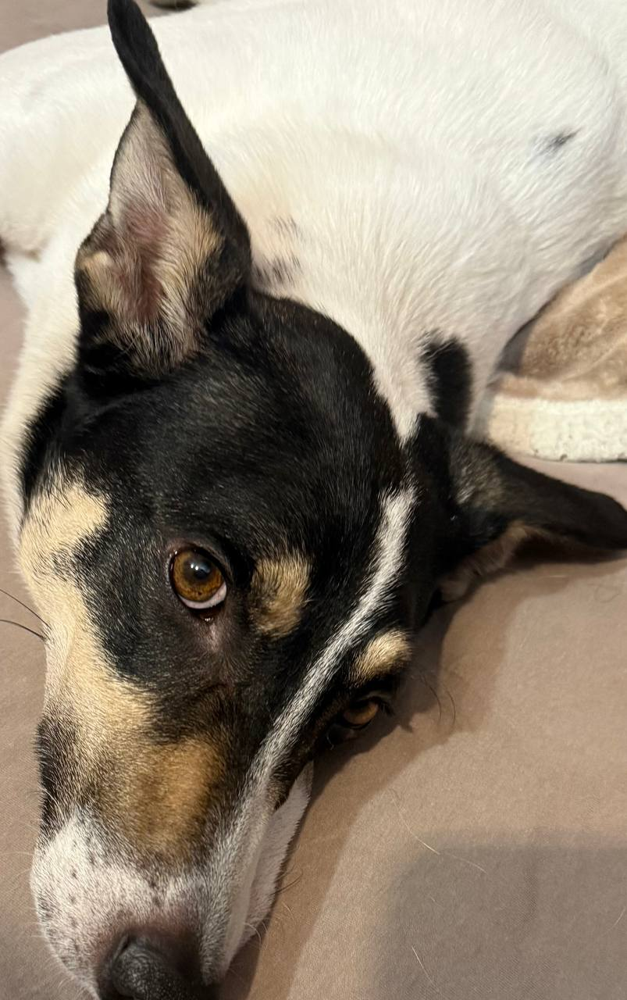

In [7]:
from PIL import Image, ImageFilter
import numpy as np
from matplotlib import pyplot as plt

with Image.open(IMAGE_NAME) as img:
    img.load()

print('Размер (ширина, высота):', img.size)
print('Режим:', img.mode)
print('Формат файла:', img.format)
display(img)

Чтобы удобно выводить несколько картинок в ряд, напишем маленькую функцию:

In [8]:
def show(images, titles=None, size=(15, 5)):
    fig, axes = plt.subplots(1, len(images), figsize=size)
    if len(images) == 1:
        axes = [axes]
    for i, im in enumerate(images):
        axes[i].imshow(im)
        axes[i].axis('off')
        if titles:
            axes[i].set_title(titles[i])
    plt.show()

# 1. Изменение размера

- `crop` — вырезать прямоугольный кусок;
- `resize` — задать точный новый размер;
- `reduce` — уменьшить в целое число раз;
- `thumbnail` — сделать миниатюру (меняет сам объект, поэтому работаем с копией).



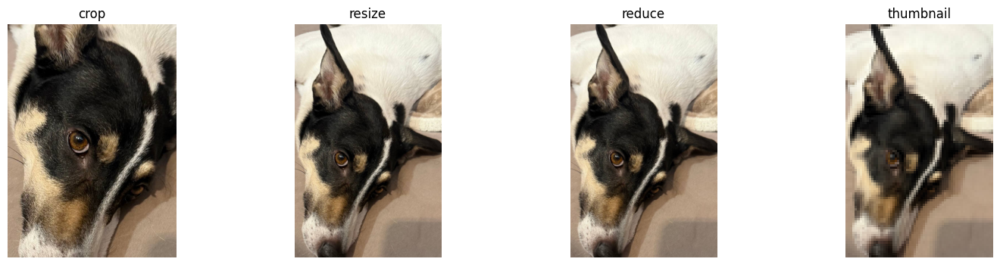

(602, 832) (267, 426) (201, 320) (63, 100)


In [9]:
w, h = img.size

# crop: (левый край, верх, правый край, низ)
crop_img = img.crop((0, h // 4, w * 3 // 4, h * 9 // 10))

# resize: уменьшаем в 3 раза
resize_img = img.resize((w // 3, h // 3))

# reduce: уменьшаем в 4 раза
reduce_img = img.reduce(4)

# thumbnail: вписываем в рамку 200x100, пропорции сохраняются
thumb = img.copy()
thumb.thumbnail((200, 100))

show([crop_img, resize_img, reduce_img, thumb],
     ['crop', 'resize', 'reduce', 'thumbnail'], (18, 4))
print(crop_img.size, resize_img.size, reduce_img.size, thumb.size)

In [10]:
print(img.size)

(803, 1280)


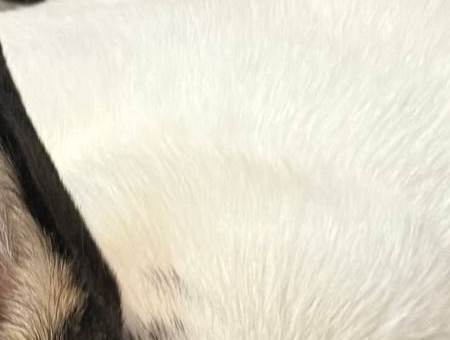

In [11]:
crop_img = img.crop((200, 10, 650, 350))
crop_img

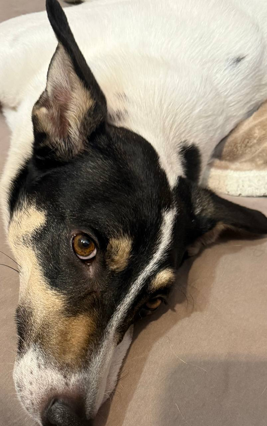

In [12]:
nw, nh = img.width // 3, img.height // 3
resize_img = img.resize((nw, nh))
resize_img

Сохранить результат в файл можно методом `save` (формат берётся из расширения):

In [13]:
resize_img.save('resized.png')

Для сохранения изображения используется функция `save`

In [14]:
resize_img.save('resized.png')

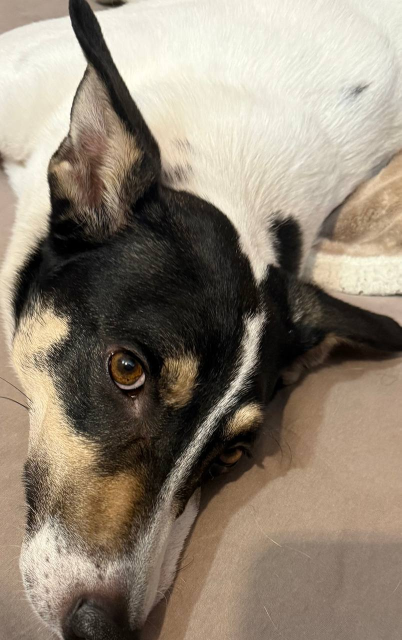

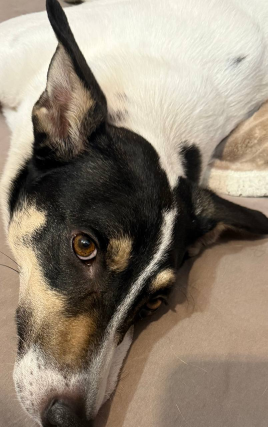

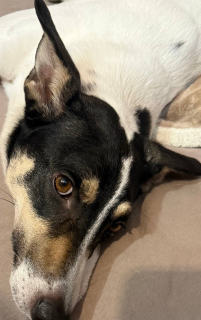

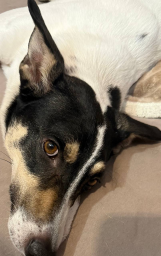

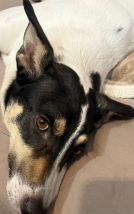

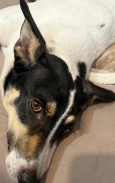

In [15]:
# reduce
for factor in range(2, 8):
  reduce_img = img.reduce(factor)
  display(reduce_img)
  print()

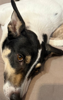

In [16]:
# thumbnail
img1=img.copy()
img1.thumbnail((200,100))
img1

## 2. Трансформации

- `transpose` — простые повороты и отражения;
- `rotate` — поворот на любой угол (`expand=True` увеличивает холст, чтобы картинка не обрезалась).

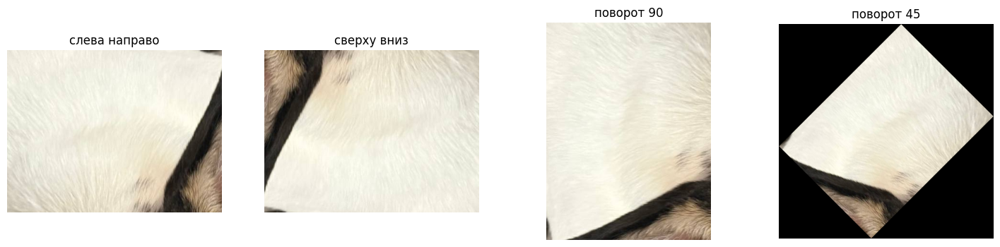

In [17]:
flip_lr = crop_img.transpose(Image.Transpose.FLIP_LEFT_RIGHT)   # зеркало слева направо
flip_tb = crop_img.transpose(Image.Transpose.FLIP_TOP_BOTTOM)   # зеркало сверху вниз
rot90   = crop_img.transpose(Image.Transpose.ROTATE_90)         # поворот на 90 градусов
rot45   = crop_img.rotate(45, expand=True)                      # поворот на 45 градусов

show([flip_lr, flip_tb, rot90, rot45],
     ['слева направо', 'сверху вниз', 'поворот 90', 'поворот 45'], (18, 4))

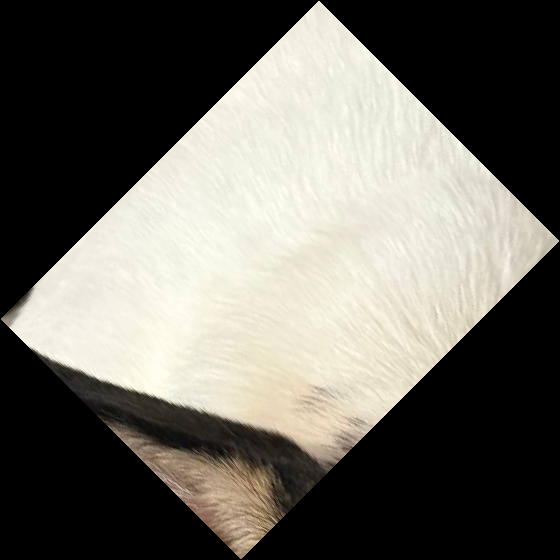

In [18]:
r_img = crop_img.rotate(45, expand=True)
r_img

## Слои, форматы, градации

Для конвертации изображения используется функция convert(mode). Возможные значения mode:
* 1 (1-bit pixels, black and white, stored with one pixel per byte)

* L (8-bit pixels, black and white)

* P (8-bit pixels, mapped to any other mode using a color palette)

* RGB (3x8-bit pixels, true color)

* RGBA (4x8-bit pixels, true color with transparency mask)

* CMYK (4x8-bit pixels, color separation)

* YCbCr (3x8-bit pixels, color video format)

* LAB (3x8-bit pixels, the L*a*b color space)

* HSV (3x8-bit pixels, Hue, Saturation, Value color space)

* I (32-bit signed integer pixels)

* F (32-bit floating point pixels)

('R', 'G', 'B')
('L',)


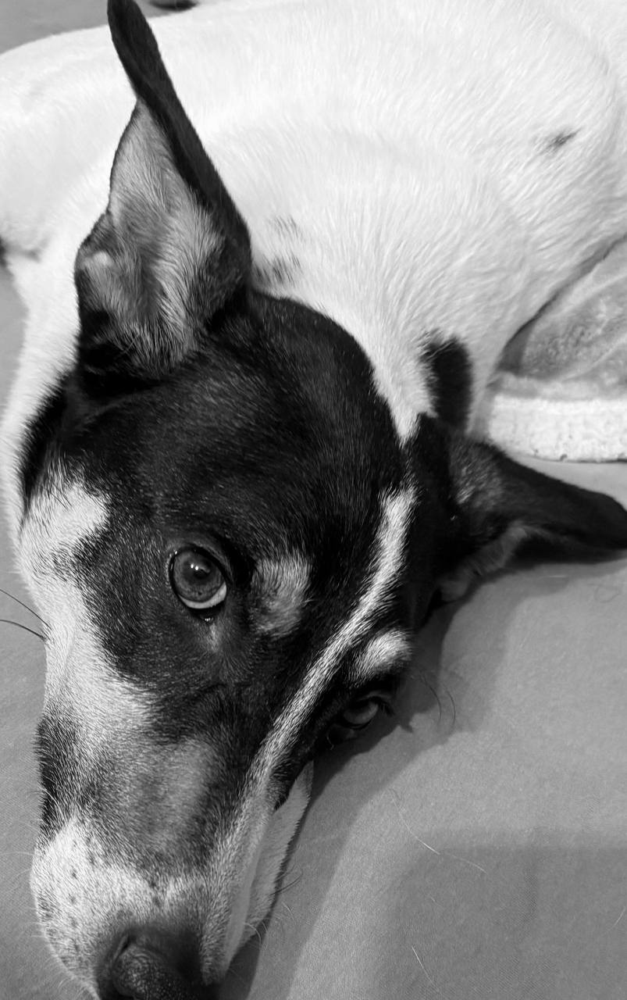

In [19]:
print(img.getbands())
cmyk_img = img.convert('L')
print(cmyk_img.getbands())
cmyk_img

Функция split() позволяет разделить изображение на каналы. Количество каналов определяется форматом изображения

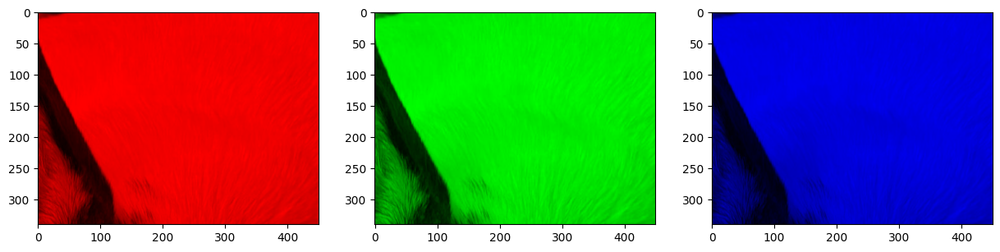

In [20]:
from matplotlib import pyplot as plt

# Выполним визуализацию зеленого, красного и синего канала для изображения RGB
red, green, blue = crop_img.split()

zeros = red.point(lambda _: 0)
red_image=Image.merge('RGB', (red, zeros, zeros))
green_image=Image.merge('RGB', (zeros, green, zeros))
blue_image=Image.merge('RGB', (zeros, zeros, blue))

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15,6))
axes[0].imshow(red_image)
axes[1].imshow(green_image)
axes[2].imshow(blue_image)

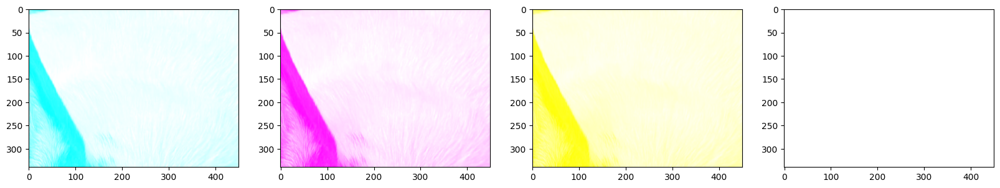

In [21]:
# Конвертируем изображение в формат CMYC
cmyk_image=crop_img.convert('CMYK')
# Выполним визуализацию каналов для изображения CMYK
C, M, Y, K = cmyk_image.split()

zeros = red.point(lambda _: 0)
c_image=Image.merge('CMYK', (C, zeros, zeros, zeros))
m_image=Image.merge('CMYK', (zeros, M, zeros, zeros))
y_image=Image.merge('CMYK', (zeros, zeros, Y, zeros))
k_image=Image.merge('CMYK', (zeros, zeros, zeros, K))

fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20,5))
axes[0].imshow(c_image)
axes[1].imshow(m_image)
axes[2].imshow(y_image)
axes[3].imshow(k_image)

## 3. Встроенные фильтры


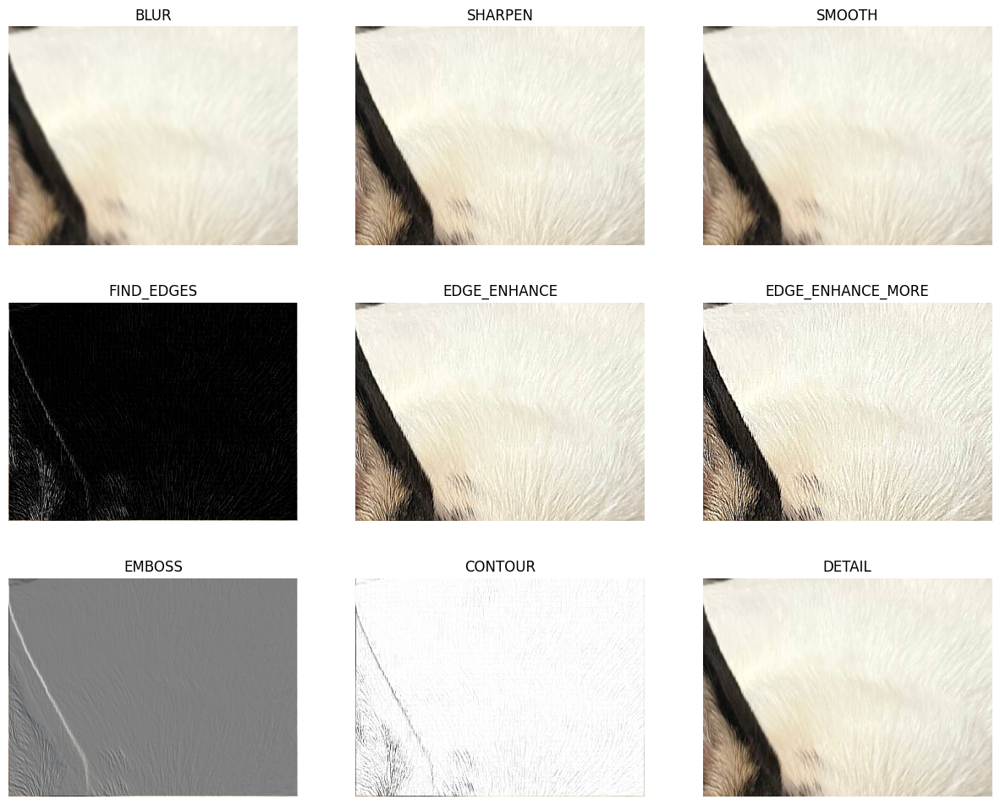

In [22]:
filters = {
    'BLUR': ImageFilter.BLUR,
    'SHARPEN': ImageFilter.SHARPEN,
    'SMOOTH': ImageFilter.SMOOTH,
    'FIND_EDGES': ImageFilter.FIND_EDGES,
    'EDGE_ENHANCE': ImageFilter.EDGE_ENHANCE,
    'EDGE_ENHANCE_MORE': ImageFilter.EDGE_ENHANCE_MORE,
    'EMBOSS': ImageFilter.EMBOSS,
    'CONTOUR': ImageFilter.CONTOUR,
    'DETAIL': ImageFilter.DETAIL,
}

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, (name, f) in zip(axes.flat, filters.items()):
    ax.imshow(crop_img.filter(f))
    ax.set_title(name)
    ax.axis('off')
plt.show()

В библиотеке Pillow доступно большое количество фильтров различного назначения

## 5. Операции над пикселями через numpy

Изображение можно превратить в массив чисел (`np.array`) и менять его арифметикой.

**Уменьшение числа цветов.** Делим значение пикселя нацело и умножаем обратно — получаются «ступеньки» цвета.

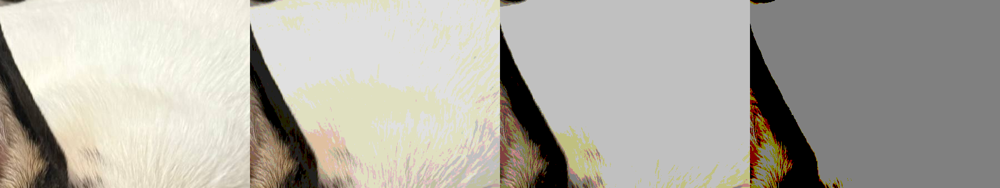

In [27]:
#
im = np.array(crop_img)
im_32 = im // 32 * 32
im_64 = im // 64 * 64
im_128 = im // 128 * 128
Image.fromarray(np.concatenate((im, im_32, im_64, im_128), axis=1))

**Инвертирование** (негатив): из 255 вычитаем значение пикселя.

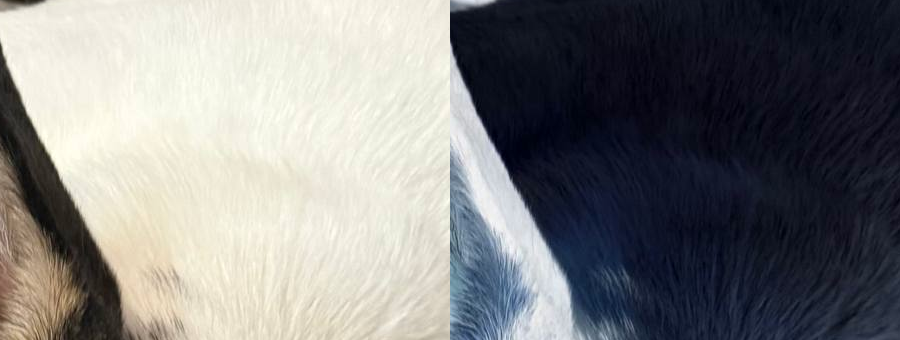

In [28]:
im_i = 255 - im
Image.fromarray(np.concatenate((im, im_i), axis=1))

**Гамма-коррекция** делает изображение светлее или темнее: пиксель возводится в степень.

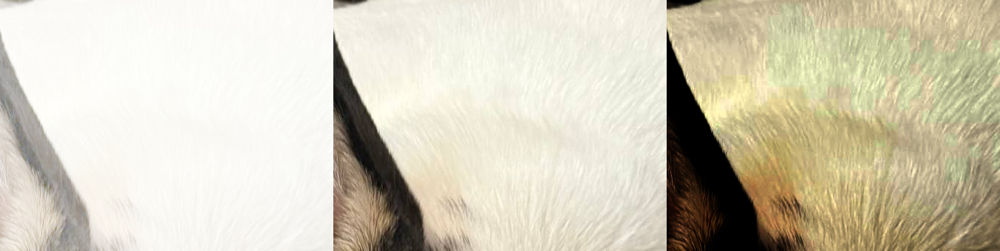

In [29]:
imf = np.array(crop_img, np.float32)
lighter = 255.0 * (imf / 255.0) ** (1 / 4.2)
darker = 255.0 * (imf / 255.0) ** 4.2
Image.fromarray(np.uint8(np.concatenate((lighter, imf, darker), axis=1)))

**Обрезка срезом массива** и эффект «подсветки» нужной области: всё затемняем, а выбранный прямоугольник оставляем как есть.

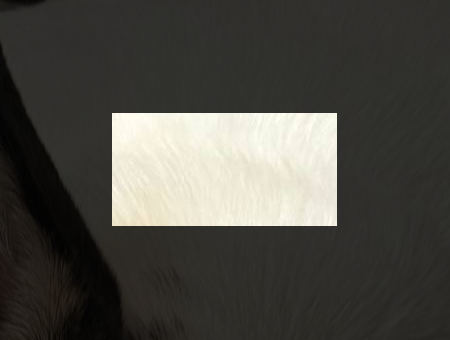

In [30]:
src = np.array(crop_img)
dst = src // 5
y0, y1, x0, x1 = src.shape[0] // 3, src.shape[0] * 2 // 3, src.shape[1] // 4, src.shape[1] * 3 // 4
dst[y0:y1, x0:x1] = src[y0:y1, x0:x1]
Image.fromarray(dst)

## 6. Свой фильтр: «Мультяшный»

### Идея

Хочется превратить фотографию в картинку, похожую на рисунок из мультфильма. У такого рисунка две главные особенности:
1. **Мало цветов** - большие участки закрашены ровным цветом.
2. **Тёмные контуры** - предметы обведены чёрной линией.

### Как фильтр работает (по шагам)

1. **Сглаживаем** картинку фильтром `MedianFilter`. Он убирает мелкие детали и шум (шерсть, текстуры), но границы остаются чёткими.
2. **Уменьшаем число цветов** (делим на шаг и умножаем обратно), как в разделе 5.
3. **Находим границы**: переводим картинку в серую, размываем (чтобы не ловить мелкий шум, например складки ткани) и применяем `FIND_EDGES`.
4. **Оставляем только сильные границы** (порог `edge_threshold`) и делаем линии чуть толще фильтром `MaxFilter`.
5. **Рисуем чёрные контуры** поверх цветной картинки.

У фильтра два параметра: `levels` - сколько примерно цветовых уровней оставить (меньше — «мультяшнее», обычно от 4 до 16), и `edge_threshold` - чувствительность к границам (меньше - больше линий, обычно от 8 до 30).

In [31]:
def cartoon(image, levels=8, edge_threshold=15):
    rgb = image.convert('RGB')

    # 1. сглаживание
    smooth = rgb.filter(ImageFilter.MedianFilter(7))

    # 2. уменьшение числа цветов
    step = 256 // levels
    arr = np.array(smooth).astype(int)
    arr = arr // step * step + step // 2
    arr = np.clip(arr, 0, 255).astype(np.uint8)

    # 3. поиск границ (перед этим размываем, чтобы не ловить мелкий шум)
    gray = rgb.convert('L').filter(ImageFilter.GaussianBlur(2))
    edges = gray.filter(ImageFilter.FIND_EDGES)

    # 4. оставляем только сильные границы и делаем линии толще
    edges = edges.point(lambda p: 255 if p > edge_threshold else 0)
    mask = np.array(edges.filter(ImageFilter.MaxFilter(3)))

    # у самого края кадра FIND_EDGES рисует ложную рамку, убираем её
    mask[:3, :] = 0
    mask[-3:, :] = 0
    mask[:, :3] = 0
    mask[:, -3:] = 0

    # 5. рисуем чёрные контуры
    arr[mask > 0] = 0
    return Image.fromarray(arr)


## Инвертирование изображения

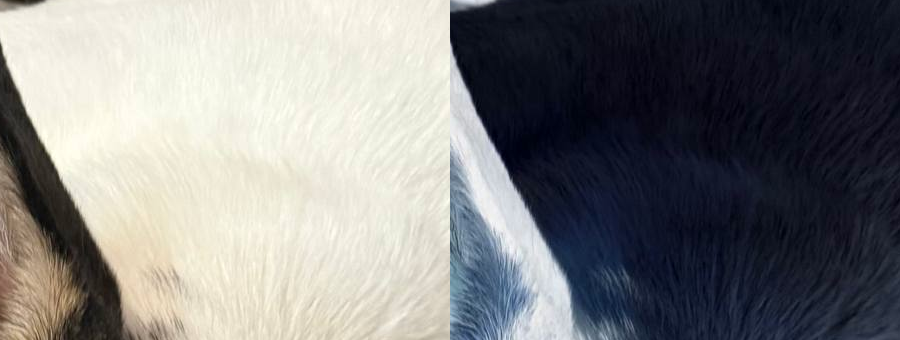

In [25]:
im = np.array(crop_img)
im_i = 255 - im
im_dec = np.concatenate((im, im_i), axis=1)
Image.fromarray(im_dec)

### Демонстрация работы

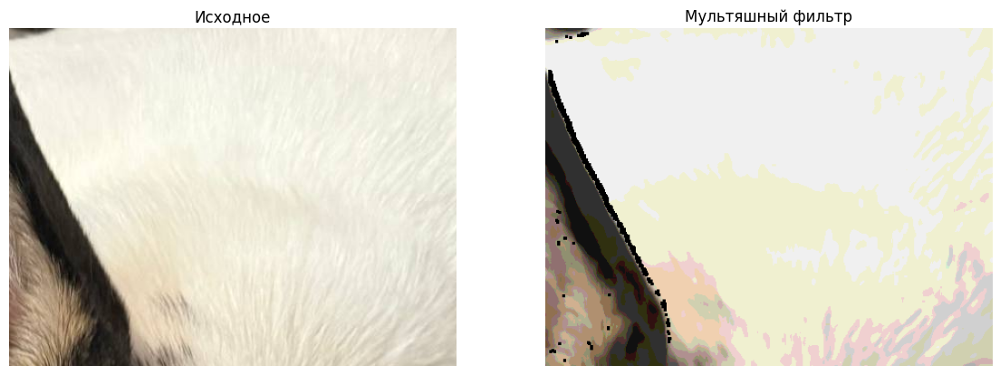

In [32]:
result = cartoon(crop_img)
show([crop_img, result], ['Исходное', 'Мультяшный фильтр'], (14, 6))

Посмотрим, как влияют параметры. Слева — мало цветов и мало линий, справа — больше цветов и больше линий.

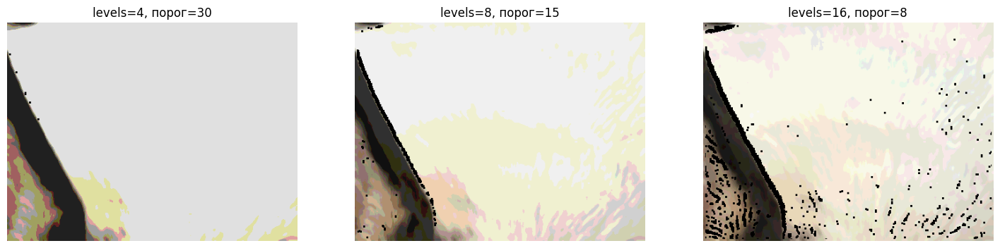

In [33]:
show([cartoon(crop_img, levels=4, edge_threshold=30),
      cartoon(crop_img, levels=8, edge_threshold=15),
      cartoon(crop_img, levels=16, edge_threshold=8)],
     ['levels=4, порог=30', 'levels=8, порог=15', 'levels=16, порог=8'], (18, 5))

### Для чего нужен такой фильтр

- **Стилизация фото** под рисунок: аватарки, открытки, эффекты в приложениях.
- **Упрощение картинки**: меньше цветов — проще печатать, вышивать, делать трафарет или раскраску.
- **Основа для распознавания**: упрощённая картинка с чёткими контурами удобнее для поиска объектов.

Главное, что мы показали: сложный фильтр можно собрать «из кирпичиков» Pillow и numpy: сглаживание, дискретизация цветов и поиск границ.

## Контрольные вопросы

### 1. Перечислите функции для трансформации изображения: вращение, обрезка и т.д.

- `crop(box)` - обрезка;
- `resize(size)` - изменение размера до точных значений;
- `reduce(factor)` - уменьшение в целое число раз;
- `thumbnail(size)` - миниатюра с сохранением пропорций (меняет сам объект);
- `rotate(angle)` - поворот на любой угол;
- `transpose(...)` - повороты на 90/180/270 градусов и отражения (`FLIP_LEFT_RIGHT`, `FLIP_TOP_BOTTOM`);
- `paste(...)` - вставка одного изображения в другое;
- `ImageOps.mirror`, `ImageOps.flip` - зеркальное отражение.
small = img.resize((200, 150))
for name, im in [('crop', small.crop((0, 0, 100, 75))),
                 ('rotate 30', small.rotate(30)),
                 ('transpose', small.transpose(Image.Transpose.ROTATE_180))]:
    print(name, im.size)
    ### 2. Назначение метода `convert()` и значения его параметра

`convert(mode)` создаёт копию изображения в другом **режиме**, то есть меняет способ хранения цвета (например, цветное делает чёрно-белым). Возможные значения `mode`:

| Режим | Что означает |
|---|---|
| `1` | 1 бит на пиксель, только чёрный и белый |
| `L` | 8 бит, оттенки серого |
| `P` | 8 бит, цвета берутся из палитры |
| `RGB` | 3 канала по 8 бит, полноцветное |
| `RGBA` | RGB + канал прозрачности |
| `CMYK` | 4 канала (голубой, пурпурный, жёлтый, чёрный), для печати |
| `YCbCr` | цветовой формат видео (яркость + две цветовые составляющие) |
| `LAB` | цветовое пространство L*a*b |
| `HSV` | оттенок, насыщенность, яркость |
| `I` | 32-битные целые числа |
| `F` | 32-битные дробные числа |
for mode in ['1', 'L', 'RGB', 'RGBA', 'CMYK', 'HSV']:
    converted = img.convert(mode)
    print(mode, '->', converted.getbands())
    ### 3. Что такое фильтрация изображений? Примеры применения

**Фильтрация** - это обработка изображения, при которой новое значение каждого пикселя считается по нему самому и его соседям. Чаще всего берут маленькую таблицу чисел (ядро, например 3x3), накладывают её на каждый пиксель, умножают, складывают - это называется *свёртка*. От чисел в ядре зависит результат.

Примеры использования:
- **размытие** - убрать шум, скрыть детали (например, номера или лица);
- **повышение резкости** - улучшить нечёткие фото и сканы;
- **поиск границ** - первый шаг для распознавания объектов, лиц, текста;
- **тиснение** (`EMBOSS`) и художественные эффекты;
- подготовка изображения для компьютерного зрения и медицинских снимков.
# Пример: простое размытие и повышение резкости
show([small, small.filter(ImageFilter.BLUR), small.filter(ImageFilter.SHARPEN)],
     ['Исходное', 'BLUR', 'SHARPEN'], (12, 4))
### 4. Формат изображения RGB

RGB - это способ описания цвета тремя составляющими: **R**ed (красный), **G**reen (зелёный), **B**lue (синий). Любой цвет получается смешиванием этих трёх. Обычно на каждый канал отводится 8 бит, то есть значение от 0 до 255, значит на пиксель уходит 24 бита (3 байта).

Примеры: `(0, 0, 0)` - чёрный, `(255, 255, 255)` - белый, `(255, 0, 0)` - красный, `(255, 255, 0)` - жёлтый. Так устроены экраны мониторов и телефонов.
px = img.convert('RGB').getpixel((10, 10))
print('Цвет пикселя (R, G, B):', px)

arr = np.array(img.convert('RGB'))
print('Форма массива (высота, ширина, каналы):', arr.shape)
### 5. Значение терминов

- **Растр** - изображение в виде сетки маленьких цветных квадратиков (пикселей). Если сильно увеличить, видны отдельные пиксели. Противоположность - векторная графика, где картинка описана линиями и формулами.
- **Формат изображения** - способ хранения картинки в файле: JPEG (сжатие с потерей качества, для фото), PNG (без потерь, есть прозрачность), GIF (до 256 цветов, анимация), BMP (без сжатия).
- **Палитра** - набор цветов, которые можно использовать в картинке. В режиме `P` пиксель хранит не сам цвет, а номер цвета в палитре.
- **Глубина** (глубина цвета) - сколько бит отводится на пиксель. 1 бит - 2 цвета, 8 бит - 256 цветов или оттенков серого, 24 бита (RGB) - около 16,7 млн цветов.
- **Разрешение** - размер изображения в пикселях (например, 1920x1080), а также плотность пикселей при печати (dpi): чем она выше, тем чётче картинка.
print('Формат файла:', img.format)
print('Режим (способ хранения цвета):', img.mode)
print('Разрешение в пикселях:', img.size)
print('Плотность (dpi):', img.info.get('dpi', 'не указана'))

p_img = img.convert('P')   # режим с палитрой
print('Режим P, первые числа палитры:', p_img.getpalette()[:9])
### 6. Возможности библиотеки Pillow. Примеры методов

Pillow умеет:
- **открывать и сохранять** множество форматов (`Image.open`, `save`);
- **менять размер и форму** (`resize`, `crop`, `thumbnail`, `rotate`, `transpose`);
- **менять режим и каналы** (`convert`, `split`, `merge`);
- **применять фильтры** (`filter`, модуль `ImageFilter`);
- **менять цвет и яркость** (`ImageEnhance`: яркость, контраст, насыщенность, резкость; `ImageOps`: автоконтраст, негатив, оттенки серого);
- **рисовать и писать текст** (`ImageDraw`, `ImageFont`);
- **вставлять одно изображение в другое** (`paste`, `alpha_composite`);
- **работать с отдельными пикселями** (`getpixel`, `putpixel`, `point`) и вместе с numpy.

Примеры методов, которые изменяют изображение:
from PIL import ImageEnhance, ImageOps, ImageDraw

bright = ImageEnhance.Brightness(small).enhance(1.5)      # ярче
contrast = ImageEnhance.Contrast(small).enhance(1.8)      # контрастнее
inverted = ImageOps.invert(small.convert('RGB'))          # негатив

drawn = small.copy()
draw = ImageDraw.Draw(drawn)
draw.rectangle((10, 10, 120, 70), outline='red', width=3)  # рамка
draw.text((15, 75), 'Pillow', fill='yellow')               # надпись

show([bright, contrast, inverted, drawn],
     ['ярче', 'контрастнее', 'негатив', 'рамка и текст'], (18, 4))